
# Lung Cancer Prediction

**Author:** _Luke Profio_  
**Date:** 2025-07-01


In [1]:

# -----------------------------
# 1. Imports & Settings
# -----------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_curve, auc)
import seaborn as sns

# inline plots for notebook
%matplotlib inline
sns.set(style="whitegrid")


In [3]:

# -----------------------------
# 2. Load the Dataset
# -----------------------------
DATA_PATH = '~/Downloads/survey lung cancer.csv'  # ensure this file is in the same directory as the notebook
df = pd.read_csv(DATA_PATH)

# Clean column names: strip spaces and replace with underscore
df.columns = df.columns.str.strip().str.replace(' ', '_')

print(f"Dataset shape: {df.shape}")
df.head()


Dataset shape: (309, 16)


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


In [4]:

# -----------------------------
# 3. Initial Inspection
# -----------------------------
# Basic information
display(df.info())

# Check for missing values
display(df.isnull().sum().to_frame('missing'))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   GENDER                 309 non-null    object
 1   AGE                    309 non-null    int64 
 2   SMOKING                309 non-null    int64 
 3   YELLOW_FINGERS         309 non-null    int64 
 4   ANXIETY                309 non-null    int64 
 5   PEER_PRESSURE          309 non-null    int64 
 6   CHRONIC_DISEASE        309 non-null    int64 
 7   FATIGUE                309 non-null    int64 
 8   ALLERGY                309 non-null    int64 
 9   WHEEZING               309 non-null    int64 
 10  ALCOHOL_CONSUMING      309 non-null    int64 
 11  COUGHING               309 non-null    int64 
 12  SHORTNESS_OF_BREATH    309 non-null    int64 
 13  SWALLOWING_DIFFICULTY  309 non-null    int64 
 14  CHEST_PAIN             309 non-null    int64 
 15  LUNG_CANCER            

None

,missing
GENDER,0
AGE,0
SMOKING,0
YELLOW_FINGERS,0
ANXIETY,0
PEER_PRESSURE,0
CHRONIC_DISEASE,0
FATIGUE,0
ALLERGY,0
WHEEZING,0


In [5]:

# -----------------------------
# 4. Data Cleaning & Pre‑processing
# -----------------------------
# Map target variable 'LUNG_CANCER': YES->1, NO->0
df['LUNG_CANCER'] = df['LUNG_CANCER'].map({'YES': 1, 'NO': 0})

# Map binary survey answers: 2 → 1 (yes), 1 → 0 (no)
binary_cols = [
    col
    for col in df.columns
    if df[col].dtype != 'O' and col not in ['AGE', 'LUNG_CANCER']
]
for col in binary_cols:
    df[col] = df[col].replace({2: 1, 1: 0})

# Encode GENDER: M=1, F=0
df['GENDER'] = df['GENDER'].map({'M': 1, 'F': 0})

# Sanity check
df.head()


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,1,69,0,1,1,0,0,1,0,1,1,1,1,1,1,1
1,1,74,1,0,0,0,1,1,1,0,0,0,1,1,1,1
2,0,59,0,0,0,1,0,1,0,1,0,1,1,0,1,0
3,1,63,1,1,1,0,0,0,0,0,1,0,0,1,1,0
4,0,63,0,1,0,0,0,0,0,1,0,1,1,0,0,0



## 5. Exploratory Data Analysis (EDA)

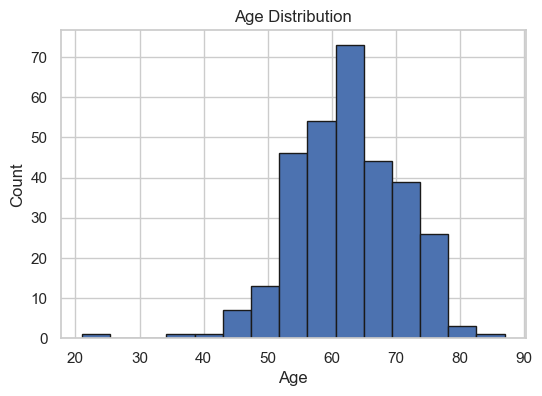

In [6]:

# Age distribution
plt.figure(figsize=(6,4))
plt.hist(df['AGE'], bins=15, edgecolor='k')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()


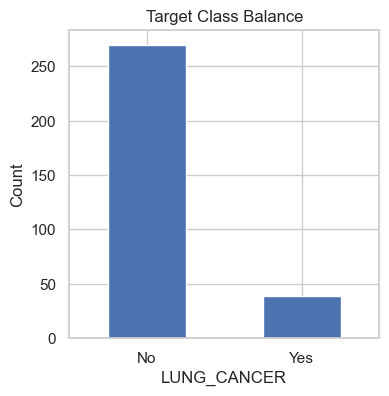

In [7]:

# Target balance
plt.figure(figsize=(4,4))
df['LUNG_CANCER'].value_counts().plot(kind='bar', rot=0)
plt.title('Target Class Balance')
plt.xticks([0,1], ['No', 'Yes'], rotation=0)
plt.ylabel('Count')
plt.show()


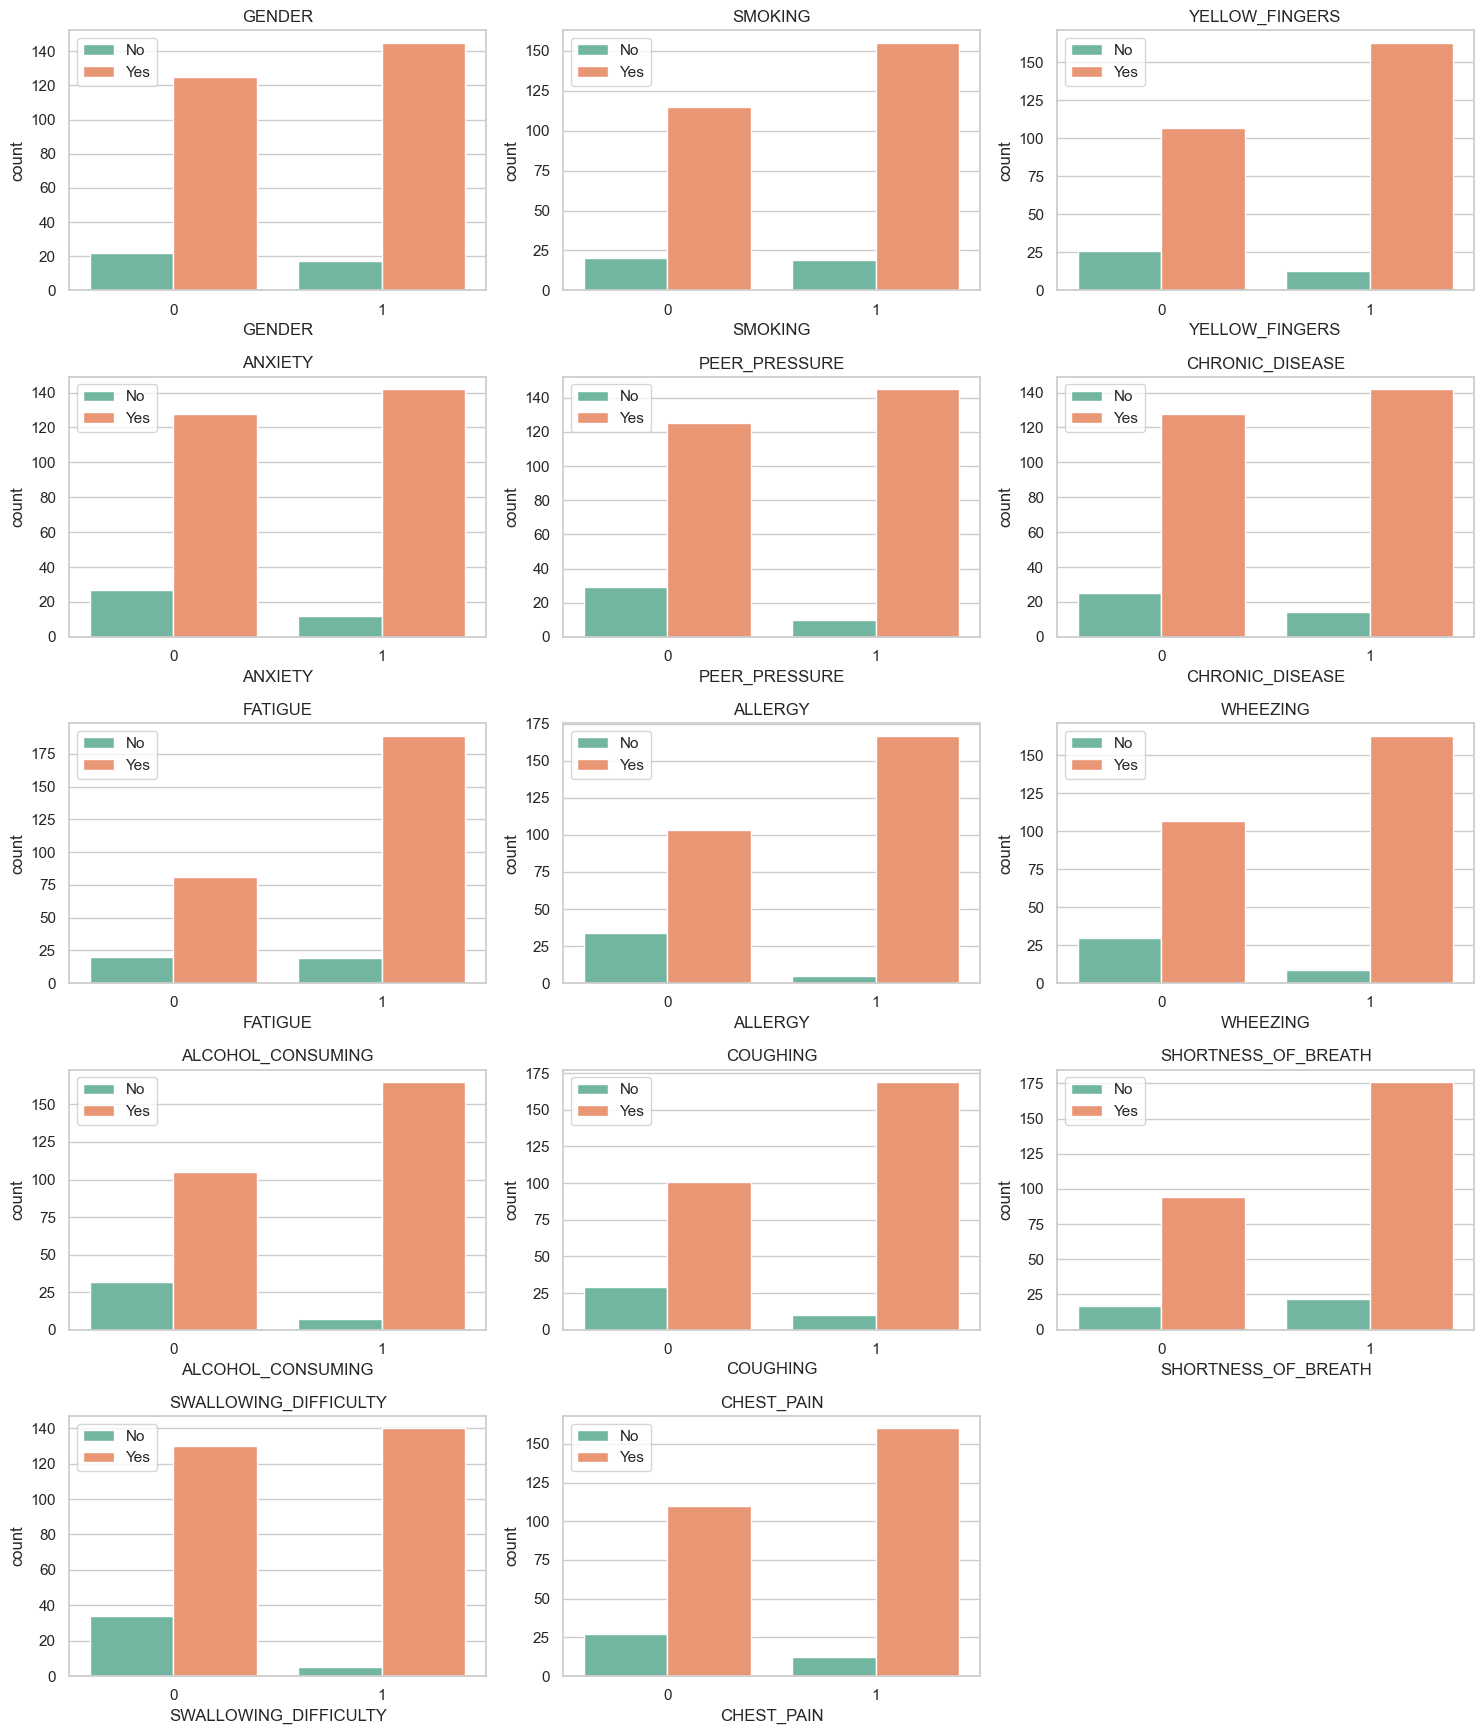

In [8]:

# Bar plots for categorical/binary features vs target
categorical_cols = ['GENDER', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE',
                    'CHRONIC_DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING',
                    'ALCOHOL_CONSUMING', 'COUGHING', 'SHORTNESS_OF_BREATH',
                    'SWALLOWING_DIFFICULTY', 'CHEST_PAIN']

n_cols = 3
n_rows = int(np.ceil(len(categorical_cols) / n_cols))
plt.figure(figsize=(15, n_rows*3.5))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.countplot(x=col, hue='LUNG_CANCER', data=df, palette='Set2')
    plt.title(col)
    plt.legend(['No', 'Yes'])
    plt.tight_layout()
plt.show()


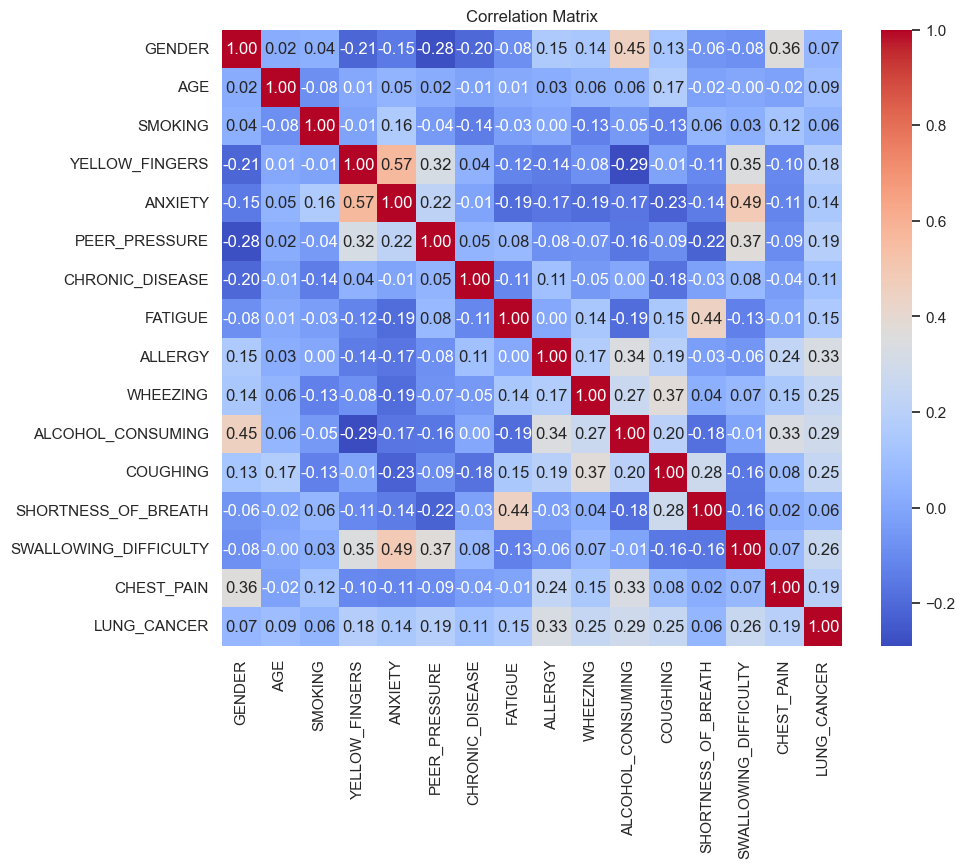

In [10]:

# Correlation heatmap
plt.figure(figsize=(10,8))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


In [17]:

# -----------------------------
# 6. Modelling
# -----------------------------
# Features & target
X = df.drop('LUNG_CANCER', axis=1)
y = df['LUNG_CANCER']

# Train‑test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train size:", X_train.shape, "Test size:", X_test.shape)


Train size: (247, 15) Test size: (62, 15)


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-

Best params: {'clf__C': 0.001, 'clf__l1_ratio': 0.0, 'clf__penalty': 'l2', 'poly__interaction_only': True}
Best CV AUC: 0.931

Classification Report
              precision    recall  f1-score   support

           0       0.42      1.00      0.59         8
           1       1.00      0.80      0.89        54

    accuracy                           0.82        62
   macro avg       0.71      0.90      0.74        62
weighted avg       0.93      0.82      0.85        62

Accuracy: 0.823


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1197: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


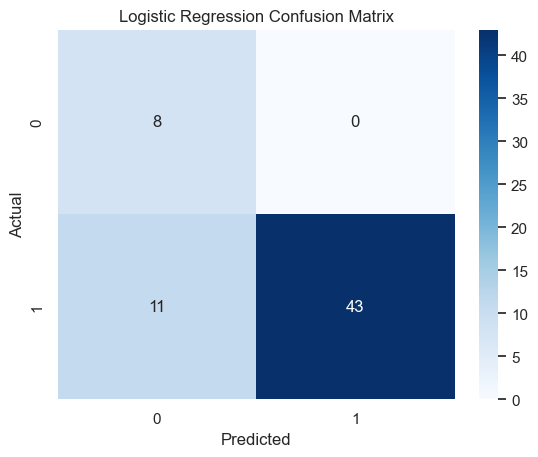

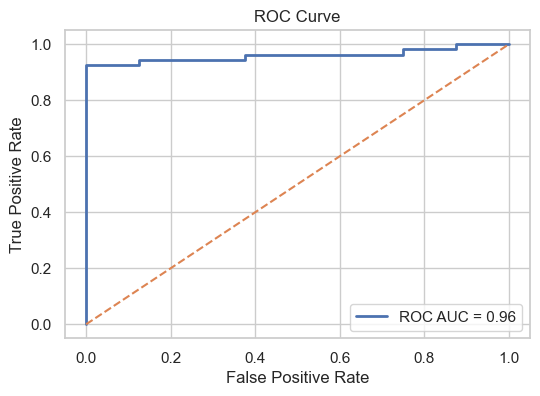

In [12]:

# 6.1 Logistic Regression with Feature Engineering, Hyperparameter Tuning & Regularization

import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report, accuracy_score,
    confusion_matrix, roc_curve, auc
)
import seaborn as sns
import matplotlib.pyplot as plt

# Model pipeline
pipe_lr = Pipeline([
    # 1. Fill any remaining missing values with the median
    ('impute', SimpleImputer(strategy='median')),
    # 2. Create new interaction terms (degree will be tuned)
    ('poly', PolynomialFeatures(interaction_only=True, include_bias=False)),
    # 3. Standardize to zero mean / unit variance
    ('scaler', StandardScaler()),
    # 4. Logistic regression supporting L1/L2/elastic-net
    ('clf', LogisticRegression(
        solver='saga',       
        max_iter=10000,      
        class_weight='balanced'  
    ))
])

# Hyperparameter grid:
param_grid = {
    'poly__interaction_only': [False, True],
    'clf__penalty':        ['l1', 'l2', 'elasticnet'],
    'clf__C':              np.logspace(-4, 4, 9),
    'clf__l1_ratio':       [0.0, 0.5, 1.0]  
}

# 5-fold stratified CV for robust AUC estimation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Grid search optimizing ROC AUC
grid_lr = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    refit=True
)

# Fit to training data
grid_lr.fit(X_train, y_train)

# ----------------------------------------------------------------
# Report best hyperparameters & CV performance
# ----------------------------------------------------------------
print("Best params:", grid_lr.best_params_)
print("Best CV AUC: {:.3f}".format(grid_lr.best_score_))

# ----------------------------------------------------------------
# Evaluate on test set
# ----------------------------------------------------------------
y_pred  = grid_lr.predict(X_test)
y_proba = grid_lr.predict_proba(X_test)[:, 1]

print("\nClassification Report")
print(classification_report(y_test, y_pred))
print("Accuracy: {:.3f}".format(accuracy_score(y_test, y_pred)))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, lw=2, label=f'ROC AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()



Classification Report (Random Forest)
              precision    recall  f1-score   support

           0       0.57      0.50      0.53         8
           1       0.93      0.94      0.94        54

    accuracy                           0.89        62
   macro avg       0.75      0.72      0.73        62
weighted avg       0.88      0.89      0.88        62

Accuracy: 0.887


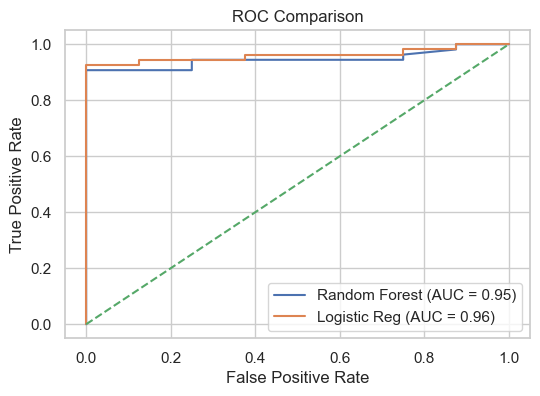

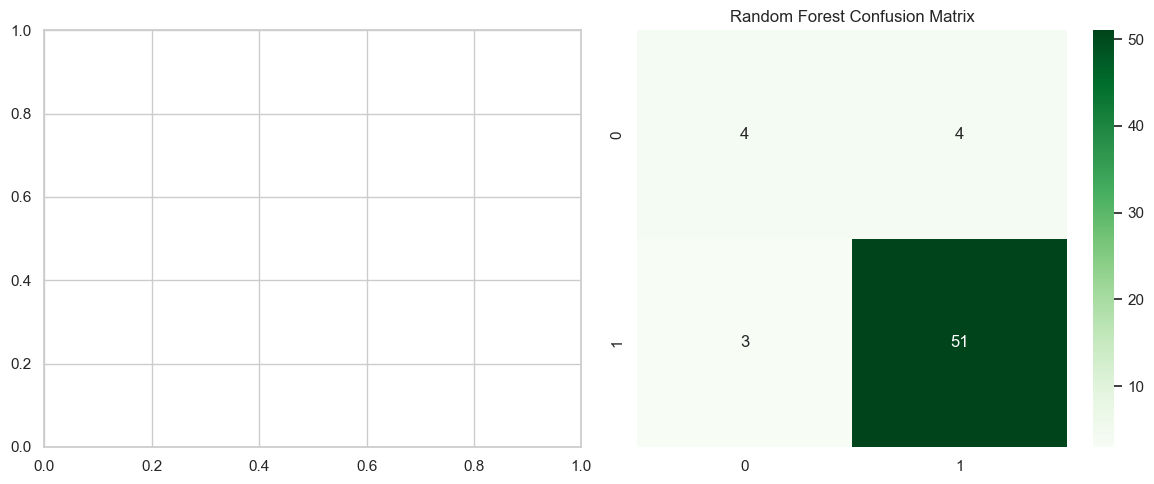

In [63]:

## 6.2 Random Forest (benchmark)

rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:,1]

print("\nClassification Report (Random Forest)")
print(classification_report(y_test, y_pred_rf))
print("Accuracy: {:.3f}".format(accuracy_score(y_test, y_pred_rf)))

# ROC curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(6,4))
plt.plot(fpr_rf, tpr_rf, label='Random Forest (AUC = %0.2f)' % roc_auc_rf)
plt.plot(fpr, tpr, label='Logistic Reg (AUC = %0.2f)' % roc_auc)
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Comparison')
plt.legend()
plt.show()


fig, axs = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', ax=axs[1], cmap="Greens")
axs[1].set_title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()


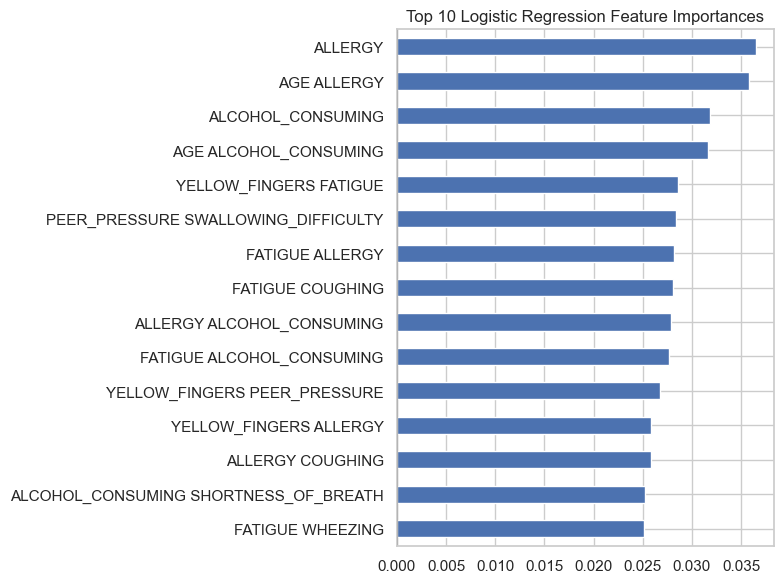

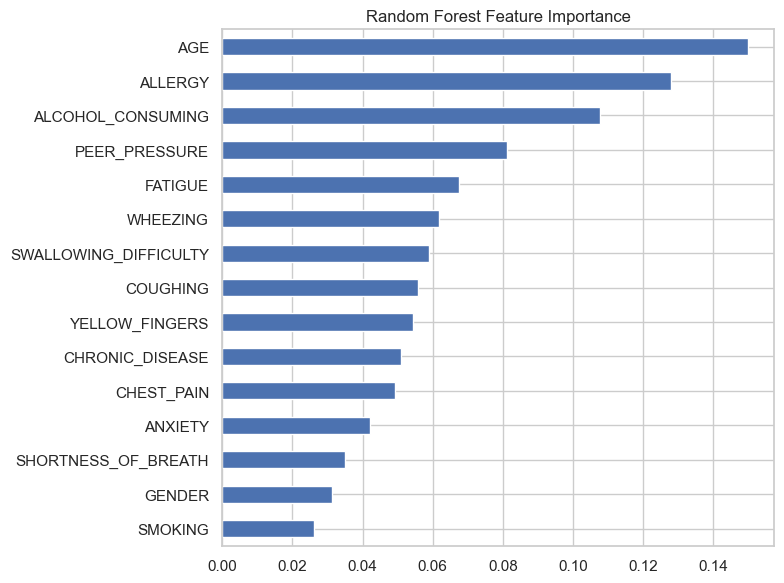

In [22]:
# -----------------------------
# 6.3 Feature Importance
# -----------------------------

poly_feature_names = grid_lr.best_estimator_.named_steps['poly'].get_feature_names_out(X.columns)

coefs = pd.Series(grid_lr.best_estimator_.named_steps['clf'].coef_[0], index=poly_feature_names)

top10_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)

top10_coefs.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Top 10 Logistic Regression Feature Importances')
plt.axvline(0, color='k')
plt.tight_layout()
plt.show()

rf_imp = pd.Series(rf.feature_importances_, index=X.columns)

rf_imp.sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()


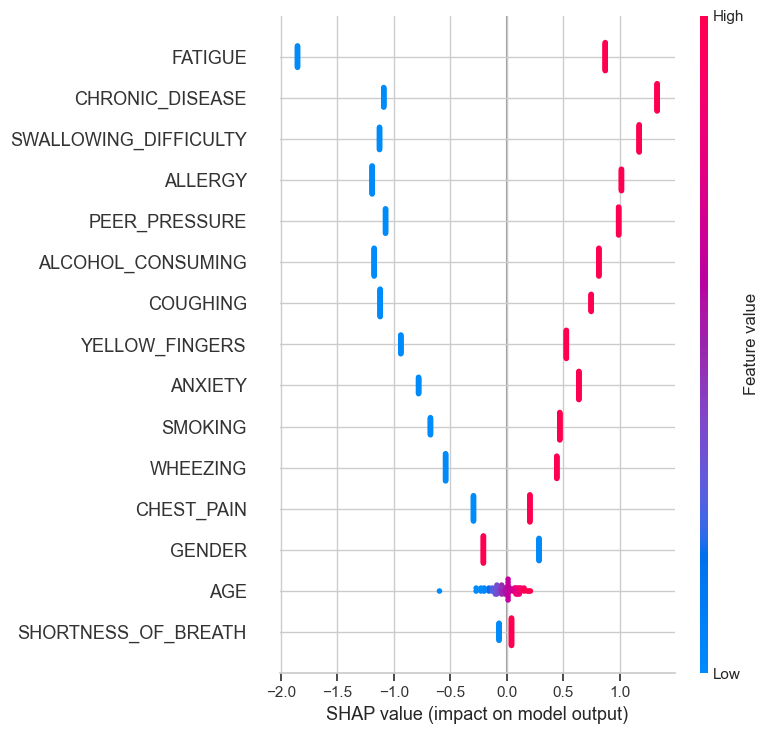

In [51]:
# -----------------------------
# SHAP for Logistic Regression (summary plot, dot format)
# -----------------------------
import shap
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Simplified pipeline (no interaction terms)
pipe_lr_simple = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(
        solver='saga',
        max_iter=10000,
        class_weight='balanced'
    ))
])

# Fit the model
pipe_lr_simple.fit(X_train, y_train)

# Prepare transformed data
X_train_proc = pd.DataFrame(
    pipe_lr_simple.named_steps['scaler'].transform(
        pipe_lr_simple.named_steps['impute'].transform(X_train)
    ),
    columns=X_train.columns
)

X_test_proc = pd.DataFrame(
    pipe_lr_simple.named_steps['scaler'].transform(
        pipe_lr_simple.named_steps['impute'].transform(X_test)
    ),
    columns=X_test.columns
)

# SHAP explanation
explainer_lr = shap.Explainer(pipe_lr_simple.named_steps['clf'], X_train_proc)
shap_values_lr = explainer_lr(X_test_proc)

# ✅ This time: no slicing — it's already 2D!
shap.summary_plot(
    shap_values_lr.values,           # shape: (n_samples, n_features)
    features=X_test_proc,
    feature_names=X_test.columns,
    plot_type="dot"
)


In [35]:
# Choose a specific index (e.g., 0, 5, or any patient row)
i = 0

# Create force plot for that prediction
shap.initjs()
shap.force_plot(
    base_value=explainer.expected_value,
    shap_values=shap_values[i],
    features=X_test_scaled[i],
    feature_names=poly_feature_names
)


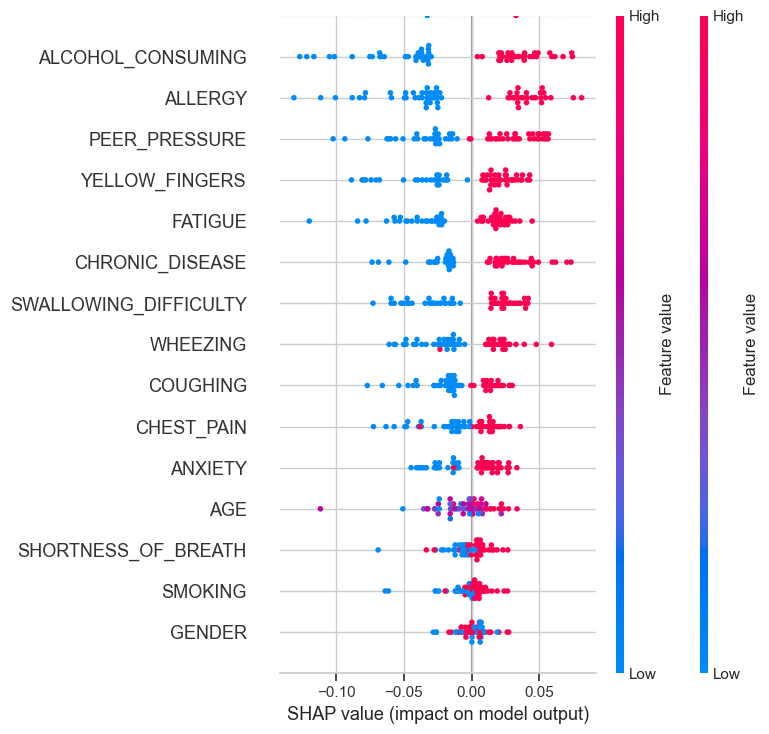

In [57]:
# -----------------------------
# SHAP for Random Forest (summary plot format)
# -----------------------------
import shap
import pandas as pd

# Ensure X_test has proper feature names
X_test_df = pd.DataFrame(X_test, columns=X_train.columns)

# Use SHAP's unified explainer (works for tree models)
explainer_rf = shap.Explainer(rf, X_train)

shap_values_rf = explainer_rf(X_test_df)  # returns shap.Explanation object

shap_vals_class1 = shap_values_rf.values[:, :, 1]  # shape: (samples, features)

# -----------------------------
# Summary plot (same format as logistic regression)
# -----------------------------
shap.summary_plot(
    shap_vals_class1,
    features=X_test_df,
    feature_names=X_test_df.columns,
    plot_type="dot"  
)


In [56]:
# Choose a specific patient index
i = 0

# Make sure the test set is a DataFrame with correct columns
X_test_df = pd.DataFrame(X_test, columns=X_train.columns)

# Force plot for class 1 (lung cancer)
shap.initjs()
shap.force_plot(
    base_value=explainer_rf.expected_value[1],
    shap_values=shap_vals_class1[i],
    features=X_test_df.iloc[i],
    feature_names=X_test_df.columns
)


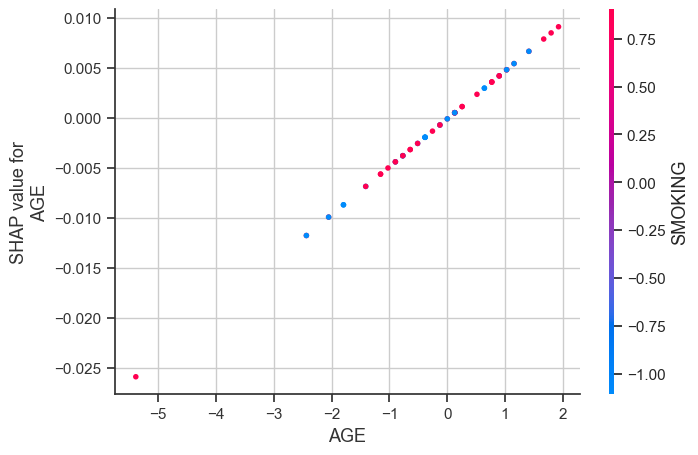

In [ ]:
# -----------------------------
# SHAP Interaction-Like Plot: Logistic Regression
# -----------------------------
import shap

X_train_imputed = grid_lr.best_estimator_.named_steps['impute'].transform(X_train)
X_train_poly = grid_lr.best_estimator_.named_steps['poly'].transform(X_train_imputed)
X_train_scaled = grid_lr.best_estimator_.named_steps['scaler'].transform(X_train_poly)

X_test_imputed = grid_lr.best_estimator_.named_steps['impute'].transform(X_test)
X_test_poly = grid_lr.best_estimator_.named_steps['poly'].transform(X_test_imputed)
X_test_scaled = grid_lr.best_estimator_.named_steps['scaler'].transform(X_test_poly)

poly_feature_names = grid_lr.best_estimator_.named_steps['poly'].get_feature_names_out(X.columns)

explainer_lr = shap.LinearExplainer(grid_lr.best_estimator_.named_steps['clf'], X_train_scaled)
shap_vals_lr = explainer_lr.shap_values(X_test_scaled)

if "AGE" in poly_feature_names and "SMOKING" in X.columns:
    shap.dependence_plot(
        "AGE",
        shap_vals_lr,
        X_test_scaled,
        feature_names=poly_feature_names,
        interaction_index=poly_feature_names.tolist().index("SMOKING")
    )
else:
    print("Required features not found in poly feature names.")

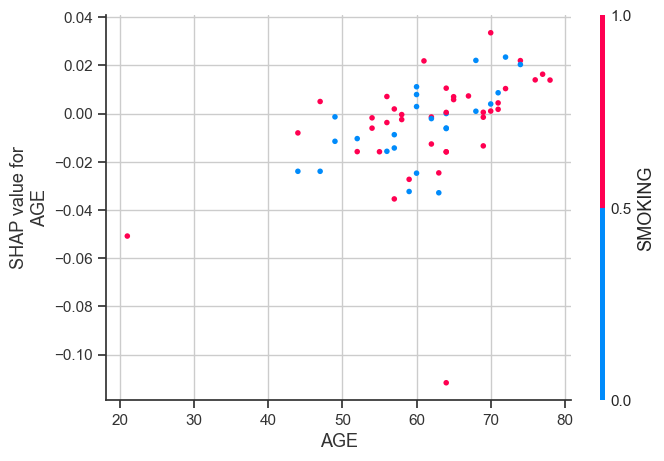

In [ ]:
# -----------------------------
# SHAP Interaction Plot: Random Forest
# -----------------------------
import shap
import pandas as pd

X_test_df = pd.DataFrame(X_test, columns=X_train.columns)

explainer_rf = shap.Explainer(rf, X_train)
shap_values_rf = explainer_rf(X_test_df)

shap_vals_class1 = shap_values_rf.values[:, :, 1]

shap.dependence_plot(
    "AGE",
    shap_vals_class1,
    X_test_df,
    interaction_index="SMOKING"
)